In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the datasets
try:
    jpn_df = pd.read_csv("/content/JPN Data.xlsx - CN_Mobiles.csv")
    in_df = pd.read_csv("/content/IN_Data.xlsx - IN_Mobiles.csv")
    print("Data loaded successfully.")
except FileNotFoundError as e:
    print(f"Error loading files: {e}. Please upload them to Colab.")

# Display basic information
print("Japanese Dataset Info:")
display(jpn_df.info())
print("\nIndian Dataset Info:")
display(in_df.info())

Data loaded successfully.
Japanese Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   ID          40000 non-null  object
 1   CURR_AGE    40000 non-null  int64 
 2   GENDER      40000 non-null  object
 3   ANN_INCOME  40000 non-null  object
 4   AGE_CAR     40000 non-null  int64 
 5   PURCHASE    40000 non-null  int64 
dtypes: int64(3), object(3)
memory usage: 1.8+ MB


None


Indian Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   ID          70000 non-null  object
 1   CURR_AGE    70000 non-null  int64 
 2   GENDER      70000 non-null  object
 3   ANN_INCOME  70000 non-null  object
 4   DT_MAINT    70000 non-null  object
dtypes: int64(1), object(4)
memory usage: 2.7+ MB


None

In [3]:
def cap_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[column] = np.where(df[column] < lower_bound, lower_bound, df[column])
    df[column] = np.where(df[column] > upper_bound, upper_bound, df[column])
    return df

In [4]:
# Extract numeric columns for Japan
numeric_cols_jpn = [col for col in jpn_df.select_dtypes(include=[np.number]).columns
                    if 'Purchase' not in col and 'ID' not in col]

# Extract numeric columns for India
numeric_cols_in = [col for col in in_df.select_dtypes(include=[np.number]).columns
                   if 'Purchase' not in col and 'ID' not in col]

# Apply capping
for col in numeric_cols_jpn:
    jpn_df = cap_outliers(jpn_df, col)

for col in numeric_cols_in:
    in_df = cap_outliers(in_df, col)

In [5]:
print(f"Japan Data Shape: {jpn_df.shape} | Missing: {jpn_df.isnull().sum().sum()}")
print(f"India Data Shape: {in_df.shape} | Missing: {in_df.isnull().sum().sum()}")

Japan Data Shape: (40000, 6) | Missing: 0
India Data Shape: (70000, 5) | Missing: 0


In [6]:
# Fix 'ANN_INCOME' by removing commas and converting to numeric
jpn_df['ANN_INCOME'] = jpn_df['ANN_INCOME'].astype(str).str.replace(',', '').astype(float)
in_df['ANN_INCOME'] = in_df['ANN_INCOME'].astype(str).str.replace(',', '').astype(float)

# Also drop the 'ID' column as it has no predictive value and will crash OneHotEncoder
jpn_df = jpn_df.drop('ID', axis=1, errors='ignore')
in_df = in_df.drop('ID', axis=1, errors='ignore')

print("Data types corrected. ID column dropped.")
print(jpn_df.dtypes)

Data types corrected. ID column dropped.
CURR_AGE      float64
GENDER         object
ANN_INCOME    float64
AGE_CAR       float64
PURCHASE      float64
dtype: object


In [7]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y) for the Japanese dataset
# Assuming 'Purchase' is your target column. Update if it is named differently (e.g., 'Target')
X_jpn = jpn_df.drop('PURCHASE', axis=1)
y_jpn = jpn_df['PURCHASE']

# Split the data with stratify=y_jpn to maintain the same ratio of buyers/non-buyers in both sets
X_train, X_test, y_train, y_test = train_test_split(X_jpn, y_jpn, test_size=0.20, random_state=42, stratify=y_jpn)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (32000, 4)
Testing set shape: (8000, 4)


In [8]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import pandas as pd

# Identify categorical and continuous columns
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
continuous_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Define the transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), continuous_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ])

# Fit on training data, transform both train and test data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Retrieve feature names for coefficient interpretation later
cat_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = continuous_cols + list(cat_feature_names)

# Convert back to DataFrames
X_train_final = pd.DataFrame(X_train_processed, columns=all_feature_names)
X_test_final = pd.DataFrame(X_test_processed, columns=all_feature_names)

In [9]:
from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply SMOTE only to the training data (never apply to test data)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_final, y_train)

print(f"Original training target distribution:\n{y_train.value_counts()}")
print(f"Resampled training target distribution:\n{y_train_resampled.value_counts()}")

Original training target distribution:
PURCHASE
1.0    18425
0.0    13575
Name: count, dtype: int64
Resampled training target distribution:
PURCHASE
1.0    18425
0.0    18425
Name: count, dtype: int64


In [10]:
from sklearn.linear_model import LogisticRegression

# Initialize and train the Logistic Regression model
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_resampled, y_train_resampled)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [11]:
import numpy as np

# Extract coefficients and map them to feature names
coefficients = log_reg.coef_[0]
feature_importance = pd.DataFrame({
    'Feature': all_feature_names,
    'Coefficient': coefficients,
    # Convert coefficient to Odds Ratio for easier business explanation
    'Odds_Multiplier': np.exp(coefficients)
})

# Sort by the most impactful features (highest absolute coefficient)
feature_importance['Abs_Coefficient'] = feature_importance['Coefficient'].abs()
feature_importance = feature_importance.sort_values(by='Abs_Coefficient', ascending=False).drop('Abs_Coefficient', axis=1)

print("Top 10 Most Impactful Features:")
display(feature_importance.head(10))

Top 10 Most Impactful Features:


,Feature,Coefficient,Odds_Multiplier
2,AGE_CAR,0.849495,2.338466
1,ANN_INCOME,0.435460,1.545674
4,GENDER_M,0.144534,1.155501
0,CURR_AGE,-0.137644,0.871409
3,GENDER_F,-0.096133,0.908343


In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

# Predict class labels and probabilities on the test dataset
y_pred = log_reg.predict(X_test_final)
y_pred_proba = log_reg.predict_proba(X_test_final)[:, 1]

# Calculate core metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

# Display evaluation metrics
print("--- Model Performance Metrics ---")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")
print("\n--- Full Classification Report ---")
print(classification_report(y_test, y_pred))

--- Model Performance Metrics ---
Accuracy : 0.6649
Precision: 0.7367
Recall   : 0.6505
F1-Score : 0.6909
ROC-AUC  : 0.7239

--- Full Classification Report ---
              precision    recall  f1-score   support

         0.0       0.59      0.68      0.63      3394
         1.0       0.74      0.65      0.69      4606

    accuracy                           0.66      8000
   macro avg       0.66      0.67      0.66      8000
weighted avg       0.67      0.66      0.67      8000



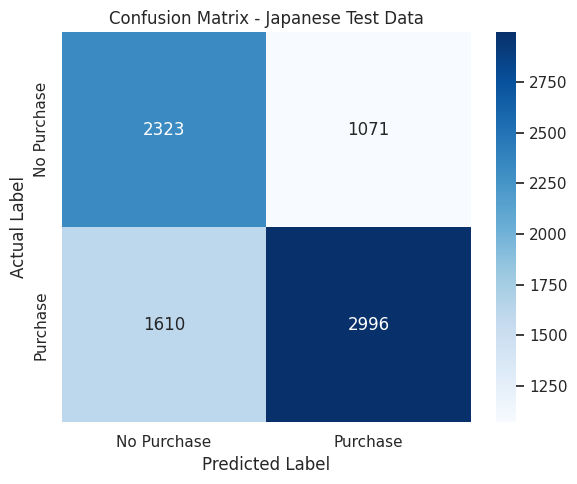

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Purchase', 'Purchase'],
            yticklabels=['No Purchase', 'Purchase'])
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - Japanese Test Data')
plt.tight_layout()
plt.show()

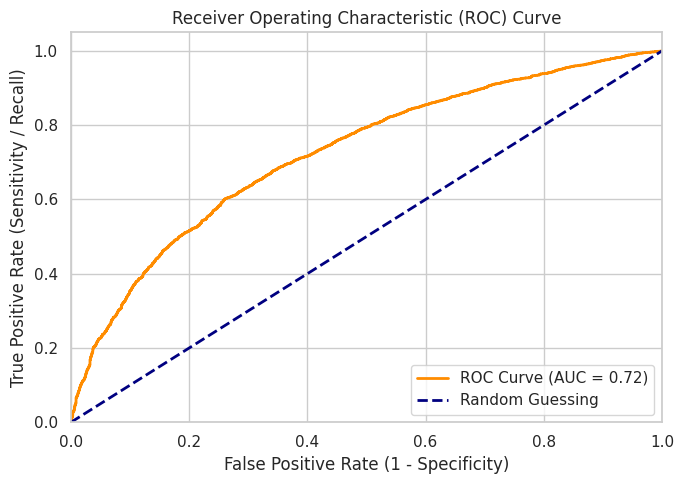

In [14]:
from sklearn.metrics import roc_curve

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import train_test_split

# 1. Align Features: Drop 'AGE_CAR' (since it's missing in India), 'ID', and 'PURCHASE'
X_jpn = jpn_df.drop(columns=['PURCHASE', 'ID', 'AGE_CAR'], errors='ignore')
y_jpn = jpn_df['PURCHASE']

# 2. Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X_jpn, y_jpn, test_size=0.20, random_state=42, stratify=y_jpn)
print(f"Training features shape: {X_train.shape}")

Training features shape: (32000, 3)


In [19]:
# Select features from Indian dataset matching the input features used for training
# Drop target variable 'PURCHASE' if present, along with 'ID'
X_in = in_df.drop(columns=['PURCHASE', 'ID'], errors='ignore')

if 'AGE_CAR' not in X_in.columns:
  X_in['AGE_CAR'] = 0
# Transform Indian data using the Japanese-fitted preprocessor
X_in_processed = preprocessor.transform(X_in,)
X_in_final = pd.DataFrame(X_in_processed, columns=all_feature_names)

# Generate predictions and probability scores for the Indian market
in_df['Predicted_Purchase'] = log_reg.predict(X_in_final)
in_df['Purchase_Probability'] = log_reg.predict_proba(X_in_final)[:, 1]

print("Predictions successfully generated for the Indian dataset.")

Predictions successfully generated for the Indian dataset.


In [20]:
# Calculate total predicted buyers and conversion metrics
total_sample_size = len(in_df)
predicted_buyers = int(in_df['Predicted_Purchase'].sum())
conversion_rate = (predicted_buyers / total_sample_size) * 100
target_threshold = 12000

print("--- Indian Market Sales Forecast ---")
print(f"Total Sample Size analyzed : {total_sample_size:,}")
print(f"Predicted Potential Buyers : {predicted_buyers:,}")
print(f"Predicted Conversion Rate  : {conversion_rate:.2f}%")
print(f"Target Sales Threshold     : {target_threshold:,}")

# Check business viability rule
if predicted_buyers >= target_threshold:
    print(f"\nDECISION: GO - Predicted sales ({predicted_buyers:,}) EXCEED the minimum threshold of {target_threshold:,} units.")
else:
    print(f"\nDECISION: NO-GO - Predicted sales ({predicted_buyers:,}) FALL SHORT of the minimum threshold of {target_threshold:,} units.")

--- Indian Market Sales Forecast ---
Total Sample Size analyzed : 70,000
Predicted Potential Buyers : 44,307
Predicted Conversion Rate  : 63.30%
Target Sales Threshold     : 12,000

DECISION: GO - Predicted sales (44,307) EXCEED the minimum threshold of 12,000 units.


In [21]:


# Extract model coefficients
coeff_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Coefficient': log_reg.coef_[0],
    'Odds_Ratio': np.exp(log_reg.coef_[0])
}).sort_values(by='Coefficient', ascending=False)

print("--- Coefficient Summary & Business Impact ---")
display(coeff_df)

print("\n--- Strategic Recommendations for ABG Motors ---")
for _, row in coeff_df.iterrows():
    feature = row['Feature']
    coef = row['Coefficient']
    odds = row['Odds_Ratio']

    if coef > 0:
        pct_increase = (odds - 1) * 100
        print(f"• POSITIVE DRIVER [{feature}]: Higher values increase purchase odds by {pct_increase:.1f}%.")
    else:
        pct_decrease = (1 - odds) * 100
        print(f"• NEGATIVE DRIVER [{feature}]: Higher values decrease purchase odds by {pct_decrease:.1f}%.")

--- Coefficient Summary & Business Impact ---


,Feature,Coefficient,Odds_Ratio
2,AGE_CAR,0.849495,2.338466
1,ANN_INCOME,0.435460,1.545674
4,GENDER_M,0.144534,1.155501
3,GENDER_F,-0.096133,0.908343
0,CURR_AGE,-0.137644,0.871409



--- Strategic Recommendations for ABG Motors ---
• POSITIVE DRIVER [AGE_CAR]: Higher values increase purchase odds by 133.8%.
• POSITIVE DRIVER [ANN_INCOME]: Higher values increase purchase odds by 54.6%.
• POSITIVE DRIVER [GENDER_M]: Higher values increase purchase odds by 15.6%.
• NEGATIVE DRIVER [GENDER_F]: Higher values decrease purchase odds by 9.2%.
• NEGATIVE DRIVER [CURR_AGE]: Higher values decrease purchase odds by 12.9%.
